# COMP 3602 – Mini Project I: Sampling Techniques + Simple Visualization
**Student:** 141962 – Moayad

## Mission 1 – Load and inspect the population
**1.** Load the CSV into `customers`.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

customers = pd.read_csv('Retail_Customers.csv')

**2.** First five rows.

In [2]:
customers.head()

,Customer_ID,Branch,Region,Customer_Type,Age,Waiting_Time_Min,Purchase_Amount_OMR,Satisfaction_Score
0,CUST0001,Nizwa,Al Dakhiliyah,Regular,42,10.1,40.30,3.4
1,CUST0002,Nizwa,Al Dakhiliyah,Regular,41,4.1,13.33,4.4
2,CUST0003,Seeb,Muscat,Premium,18,15.8,70.55,3.6
3,CUST0004,Salalah,Dhofar,Regular,55,12.2,46.59,3.8
4,CUST0005,Sohar,Al Batinah North,Regular,18,10.7,49.89,3.4


**3.** Number of rows and columns.

In [3]:
customers.shape

(1500, 8)

**4.** Column names and data types.

In [4]:
print(list(customers.columns))
customers.info()

['Customer_ID', 'Branch', 'Region', 'Customer_Type', 'Age', 'Waiting_Time_Min', 'Purchase_Amount_OMR', 'Satisfaction_Score']
<class 'pandas.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 8 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Customer_ID          1500 non-null   str    
 1   Branch               1500 non-null   str    
 2   Region               1500 non-null   str    
 3   Customer_Type        1500 non-null   str    
 4   Age                  1500 non-null   int64  
 5   Waiting_Time_Min     1500 non-null   float64
 6   Purchase_Amount_OMR  1500 non-null   float64
 7   Satisfaction_Score   1500 non-null   float64
dtypes: float64(3), int64(1), str(4)
memory usage: 93.9 KB


**5.** Customers per branch.

In [5]:
customers['Branch'].value_counts()

Branch
Muscat City    421
Seeb           291
Sohar          242
Salalah        205
Nizwa          197
Sur            144
Name: count, dtype: int64

**Go further:** most common customer type and its percentage.

In [6]:
type_pct = customers['Customer_Type'].value_counts(normalize=True) * 100
print(type_pct.round(2))
print(f"Most common: {type_pct.idxmax()} ({type_pct.max():.2f}%)")

Customer_Type
Regular     68.13
Premium     20.13
Business    11.73
Name: proportion, dtype: float64
Most common: Regular (68.13%)


## Mission 2 – Know the population before sampling
**6–8.** Population means.

In [7]:
pop_sat = customers['Satisfaction_Score'].mean()
pop_wait = customers['Waiting_Time_Min'].mean()
pop_purch = customers['Purchase_Amount_OMR'].mean()
print('Population mean satisfaction :', round(pop_sat, 3))
print('Population mean waiting time :', round(pop_wait, 3), 'min')
print('Population mean purchase     :', round(pop_purch, 3), 'OMR')

Population mean satisfaction : 3.48
Population mean waiting time : 11.058 min
Population mean purchase     : 46.088 OMR


**Think before moving on:** In a real study we normally would **not** know the population values – measuring every customer is too costly or impossible, so we sample and estimate. Here the dataset is synthetic and the whole CSV is treated as the population, so we can compute the true values and check how good each sampling method is.

## Mission 3 – Simple Random Sampling
**9.** Random sample of 100.

In [8]:
random_sample = customers.sample(n=100, random_state=42)

**10.** Sample mean vs population mean.

In [9]:
random_mean = random_sample['Satisfaction_Score'].mean()
print('Random sample mean:', round(random_mean, 3))
print('Population mean   :', round(pop_sat, 3))
print('Difference        :', round(random_mean - pop_sat, 3))

Random sample mean: 3.568
Population mean   : 3.48
Difference        : 0.088


The sample mean (≈3.57) is close to the population mean (≈3.48), differing by about 0.09.

**11.** Another sample with a different `random_state`.

In [10]:
another_sample = customers.sample(n=100, random_state=123)
print('Second sample mean:', round(another_sample['Satisfaction_Score'].mean(), 3))

Second sample mean: 3.495


No, the answer is not exactly the same (3.568 vs 3.495).

**12.** Two random samples contain different customers by chance, so their averages differ slightly (sampling variability).

**Go further:** sample sizes 50, 100, 300 – repeated with 200 different seeds each.

In [11]:
import numpy as np
rows = []
for n in [50, 100, 300]:
    means = [customers.sample(n=n, random_state=s)['Satisfaction_Score'].mean() for s in range(200)]
    rows.append({'Sample size': n, 'Mean of estimates': np.mean(means), 'Std of estimates': np.std(means)})
pd.DataFrame(rows).round(4)

,Sample size,Mean of estimates,Std of estimates
0,50,3.4817,0.0900
1,100,3.4813,0.0609
2,300,3.4794,0.0301


The spread (std) of the estimates shrinks as the sample size grows, so **n = 300** gives the most stable estimate of the population mean.

## Mission 4 – Systematic Sampling
**13.** Start at row 5, take every 15th customer.

In [12]:
start = 5
systematic_sample = customers.iloc[start::15]
print('Sample size:', len(systematic_sample))

Sample size: 100


**14–15.** Mean and comparison.

In [13]:
systematic_mean = systematic_sample['Satisfaction_Score'].mean()
print('Systematic mean:', round(systematic_mean, 3))
print('Random mean    :', round(random_mean, 3))
print('Population mean:', round(pop_sat, 3))

Systematic mean: 3.496
Random mean    : 3.568
Population mean: 3.48


**16.** The systematic sample was chosen by picking a starting row (5) and then taking every 15th customer in the list after it, so the selection follows a fixed interval rather than chance. Its mean (≈3.50) is closer to the population mean than the random sample (≈3.57).

## Mission 5 – Stratified Sampling
**17–20.** Each branch is a stratum; filter, sample 15 from each, and combine.

In [14]:
branch_samples = []
for branch in customers['Branch'].unique():
    branch_df = customers[customers['Branch'] == branch]          # 18. one DataFrame per branch
    branch_samples.append(branch_df.sample(n=15, random_state=42)) # 19. 15 customers from each
stratified_sample = pd.concat(branch_samples)                      # 20. combine
stratified_sample.shape

(90, 8)

**21.** Confirm every branch is represented.

In [15]:
print(stratified_sample['Branch'].value_counts())
print('All branches present:', set(stratified_sample['Branch']) == set(customers['Branch']))

Branch
Nizwa          15
Seeb           15
Salalah        15
Sohar          15
Muscat City    15
Sur            15
Name: count, dtype: int64
All branches present: True


**22.** Mean and comparison.

In [16]:
stratified_mean = stratified_sample['Satisfaction_Score'].mean()
print('Stratified mean:', round(stratified_mean, 3), '| Population mean:', round(pop_sat, 3), '| Difference:', round(stratified_mean - pop_sat, 3))

Stratified mean: 3.603 | Population mean: 3.48 | Difference: 0.123


The stratified mean (≈3.60) is somewhat above the population mean. Every branch is represented, but each branch gets equal weight (15) even though branches differ greatly in size, and with only 90 customers chance still matters.

## Mission 6 – Cluster Sampling
**23.** Select two whole branches.

In [17]:
selected_branches = ['Sohar', 'Nizwa']
cluster_sample = customers[customers['Branch'].isin(selected_branches)]
print('Cluster sample size:', len(cluster_sample))

Cluster sample size: 439


**24.** Mean satisfaction.

In [18]:
cluster_mean = cluster_sample['Satisfaction_Score'].mean()
print('Cluster mean:', round(cluster_mean, 3), '| Population mean:', round(pop_sat, 3))

Cluster mean: 3.681 | Population mean: 3.48


**25.** In **stratified** sampling we selected *some individuals from every branch*; in **cluster** sampling we selected *whole branches* (all customers of Sohar and Nizwa) and ignored the other four. The cluster estimate (≈3.68) is further from the population mean because the two chosen branches may not represent the other branches.

## Mission 7 – Biased sample
**26–28.** Only customers who waited less than 5 minutes.

In [19]:
biased_sample = customers[customers['Waiting_Time_Min'] < 5]
biased_mean = biased_sample['Satisfaction_Score'].mean()
print('Biased sample size:', len(biased_sample))
print('Biased mean:', round(biased_mean, 3), '| Population mean:', round(pop_sat, 3), '| Difference:', round(biased_mean - pop_sat, 3))

Biased sample size: 122
Biased mean: 4.092 | Population mean: 3.48 | Difference: 0.611


**29.** No, Python is not wrong – it calculated the mean correctly. The problem is in the **sampling design**: customers with short waits are systematically happier (waiting time and satisfaction are strongly negatively related), so this sample over-represents satisfied customers and overestimates satisfaction (≈4.09 vs ≈3.48). Correct calculation does not guarantee a valid conclusion if the sample is biased.

## Mission 8 – Visualize what sampling did
**30.** Series of means.

In [20]:
results = pd.Series({
    'Population': pop_sat,
    'Random': random_mean,
    'Systematic': systematic_mean,
    'Stratified': stratified_mean,
    'Cluster': cluster_mean,
    'Biased': biased_mean
})
results.round(3)

Population    3.480
Random        3.568
Systematic    3.496
Stratified    3.603
Cluster       3.681
Biased        4.092
dtype: float64

**31.** Bar chart.

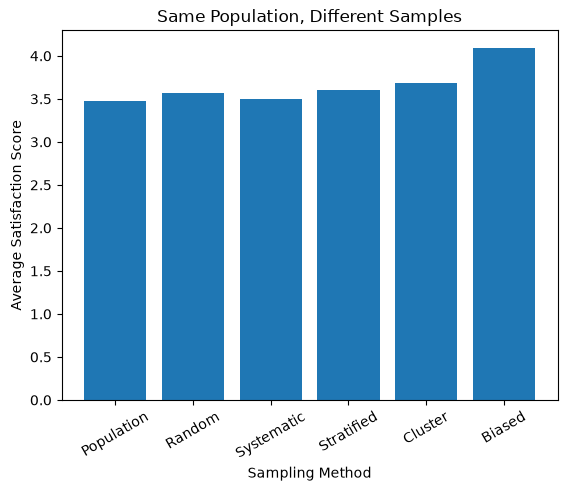

In [21]:
plt.bar(results.index, results.values)
plt.xlabel('Sampling Method')
plt.ylabel('Average Satisfaction Score')
plt.title('Same Population, Different Samples')
plt.xticks(rotation=30)
plt.show()

**32.** The **Biased** sample gives the most noticeably different estimate (≈4.09), because it only includes customers with waiting time under 5 minutes, who are systematically more satisfied.

**33.** No. A bar being close to the population value in one sample may just be luck; a method's quality depends on how the sample is selected (randomness, representation, no bias) and on repeated behaviour, not on one estimate. For example, systematic sampling can go wrong if the list has a repeating pattern, and in real studies the population mean is unknown.

## Mission 9 – Independent investigation
Claim: *"Customers who spend more money are more satisfied."*

**34.** Variables: `Purchase_Amount_OMR` (x) and `Satisfaction_Score` (y).

**35–36.** Scatter plot (two numerical variables).

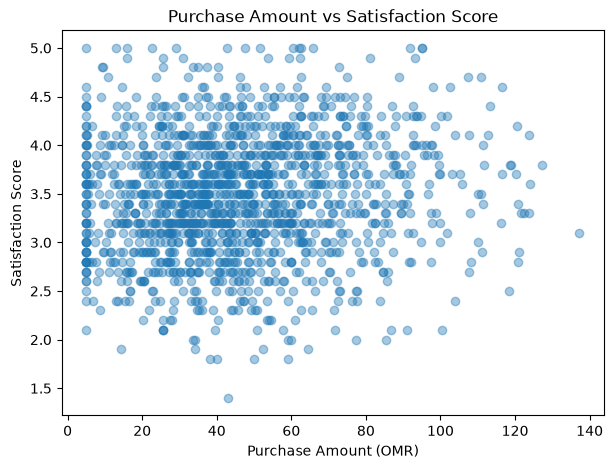

Correlation: 0.104


In [22]:
plt.figure(figsize=(7, 5))
plt.scatter(customers['Purchase_Amount_OMR'], customers['Satisfaction_Score'], alpha=0.4)
plt.xlabel('Purchase Amount (OMR)')
plt.ylabel('Satisfaction Score')
plt.title('Purchase Amount vs Satisfaction Score')
plt.show()
print('Correlation:', round(customers['Purchase_Amount_OMR'].corr(customers['Satisfaction_Score']), 3))

**37.** The scatter plot shows a cloud of points with only a very weak upward tilt, and the correlation is about 0.10. There is a slight positive **association** between purchase amount and satisfaction, but it is too weak to support the manager's statement strongly, and this association does not show causation – spending more does not necessarily make customers more satisfied.

**Go further – my own question:** *Is longer waiting time associated with lower satisfaction?*

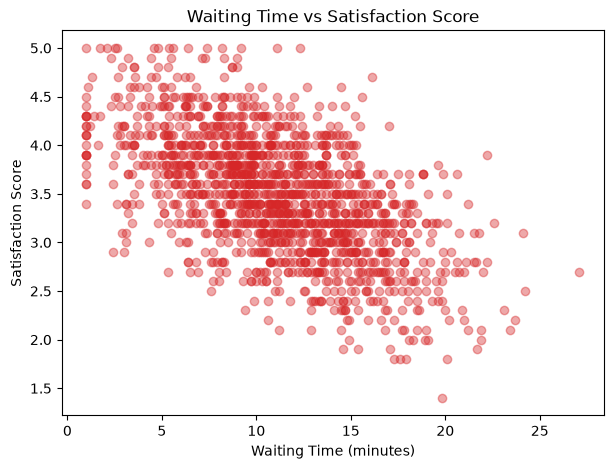

Correlation: -0.576


In [23]:
plt.figure(figsize=(7, 5))
plt.scatter(customers['Waiting_Time_Min'], customers['Satisfaction_Score'], alpha=0.4, color='tab:red')
plt.xlabel('Waiting Time (minutes)')
plt.ylabel('Satisfaction Score')
plt.title('Waiting Time vs Satisfaction Score')
plt.show()
print('Correlation:', round(customers['Waiting_Time_Min'].corr(customers['Satisfaction_Score']), 3))

The points slope clearly downward and the correlation is about −0.58: customers who wait longer tend to report lower satisfaction. This is a moderate-to-strong negative association (not proof of causation), and it is much stronger than the purchase-amount relationship, which explains the biased result in Mission 7.